# PayGuard — Step 1: Data Exploration

Goal of this notebook: download/load the PaySim dataset, understand its shape and columns, and check the class balance **before** adapting anything to a UPI schema.

Dataset: [PaySim — Synthetic Financial Datasets For Fraud Detection](https://www.kaggle.com/datasets/ealaxi/paysim1)

## 1. Download the dataset (run once)

Requires `kaggle.json` placed at `~/.kaggle/kaggle.json` (see setup steps).
If you've already downloaded the CSV manually, skip this cell and just point `DATA_PATH` below at your file.

In [1]:
# Uncomment to download via the Kaggle CLI (requires `pip install kaggle` and kaggle.json configured)
# !kaggle datasets download -d ealaxi/paysim1 -p ../data --unzip

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

DATA_PATH = "../data/PS_20174392719_1491204439457_log.csv"  # adjust filename to whatever Kaggle gives you

## 2. Load the raw data

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 6,362,620 rows x 11 columns


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## 3. Columns, dtypes, and basic info

PaySim's original columns are roughly:
- `step` — a unit of time (1 step = 1 hour, 744 steps = 30 days)
- `type` — transaction type (CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER)
- `amount` — transaction amount
- `nameOrig` — sender account id
- `oldbalanceOrg` / `newbalanceOrig` — sender balance before/after
- `nameDest` — receiver account id
- `oldbalanceDest` / `newbalanceDest` — receiver balance before/after
- `isFraud` — the label we care about
- `isFlaggedFraud` — PaySim's own naive rule flag (NOT our model — useful as a baseline to beat)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.0,NaN,NaN,NaN,243.397246,142.331971,1.0,156.0,239.0,335.0,743.0
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.0,NaN,NaN,NaN,179861.903549,603858.231463,0.0,13389.57,74871.94,208721.4775,92445516.64
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.0,NaN,NaN,NaN,833883.104074,2888242.673038,0.0,0.0,14208.0,107315.175,59585040.37
newbalanceOrig,6362620.0,NaN,NaN,NaN,855113.668579,2924048.502954,0.0,0.0,0.0,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.0,NaN,NaN,NaN,1100701.66652,3399180.112994,0.0,0.0,132705.665,943036.7075,356015889.35
newbalanceDest,6362620.0,NaN,NaN,NaN,1224996.398202,3674128.94212,0.0,0.0,214661.44,1111909.25,356179278.92
isFraud,6362620.0,NaN,NaN,NaN,0.001291,0.035905,0.0,0.0,0.0,0.0,1.0


## 4. Missing values and duplicates

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate rows: 0


## 5. Class balance — the most important check

This number is the whole reason precision/recall/F1 matter more than accuracy later.

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud rate: 0.1291%


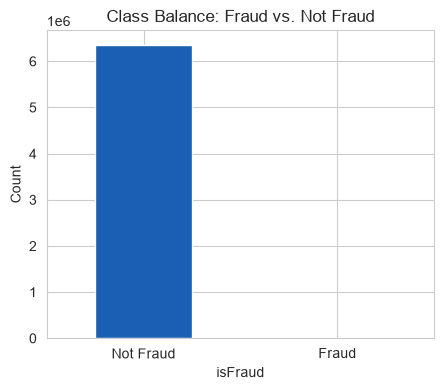

In [7]:
fraud_counts = df["isFraud"].value_counts()
fraud_pct = df["isFraud"].mean() * 100

print(fraud_counts)
print(f"\nFraud rate: {fraud_pct:.4f}%")

fraud_counts.plot(kind="bar", color=["#1A5FB4", "#C0392B"], figsize=(5, 4))
plt.xticks([0, 1], ["Not Fraud", "Fraud"], rotation=0)
plt.title("Class Balance: Fraud vs. Not Fraud")
plt.ylabel("Count")
plt.show()

## 6. Transaction type breakdown

PaySim fraud in the original dataset only ever occurs in `TRANSFER` and `CASH_OUT` types — worth confirming on your sample, since it affects how you sample/inject fraud later.

In [8]:
print(df["type"].value_counts())
print("\nFraud count by transaction type:")
print(df[df["isFraud"] == 1]["type"].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Fraud count by transaction type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


## 7. Amount distribution (fraud vs. non-fraud)

A first look at whether fraud transactions are skewed toward higher amounts — relevant for your behavioral feature design later.

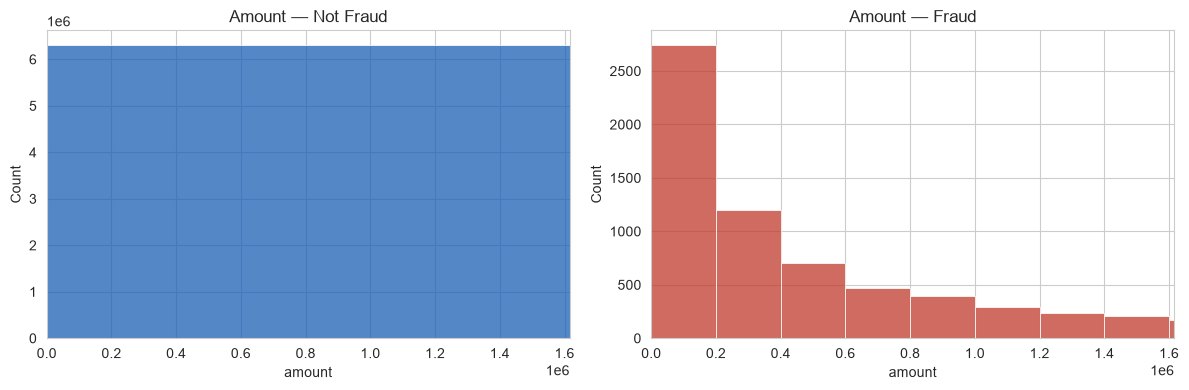

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df[df["isFraud"] == 0]["amount"], bins=50, ax=axes[0], color="#1A5FB4")
axes[0].set_title("Amount — Not Fraud")
axes[0].set_xlim(0, df["amount"].quantile(0.99))

sns.histplot(df[df["isFraud"] == 1]["amount"], bins=50, ax=axes[1], color="#C0392B")
axes[1].set_title("Amount — Fraud")
axes[1].set_xlim(0, df["amount"].quantile(0.99))

plt.tight_layout()
plt.show()

## 8. Sample a working subset (50k–100k rows)

The full PaySim dataset is ~6.3M rows — far more than you need, and slow to iterate on. Take a stratified sample so your fraud ratio is preserved, then save it for the next notebook (schema adaptation + fraud injection).

In [10]:
SAMPLE_SIZE = 80_000

fraud_df = df[df["isFraud"] == 1]
nonfraud_df = df[df["isFraud"] == 0]

# preserve the original fraud ratio in the sample
fraud_ratio = len(fraud_df) / len(df)
n_fraud_sample = int(SAMPLE_SIZE * fraud_ratio)
n_nonfraud_sample = SAMPLE_SIZE - n_fraud_sample

sample_df = pd.concat([
    fraud_df.sample(n=min(n_fraud_sample, len(fraud_df)), random_state=42),
    nonfraud_df.sample(n=n_nonfraud_sample, random_state=42),
]).sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print(f"Sample shape: {sample_df.shape}")
print(f"Sample fraud rate: {sample_df['isFraud'].mean() * 100:.4f}%")

sample_df.to_csv("../data/paysim_sample.csv", index=False)
print("Saved to ../data/paysim_sample.csv")

Sample shape: (80000, 11)
Sample fraud rate: 0.1288%
Saved to ../data/paysim_sample.csv


## Next notebook: `02_schema_adaptation_and_fraud_injection.ipynb`

- Rename columns to a UPI-style schema (sender VPA, receiver VPA, etc.)
- Inject additional synthetic fraud patterns (off-hour spikes, new-receiver anomalies)
- Produce the final dataset that feature engineering will build on